# 01 — Làm sạch và khám phá dữ liệu Telco

## Mục tiêu
Tìm hiểu các đặc điểm **liên quan** đến tình trạng rời bỏ dịch vụ, chuẩn bị dữ liệu cho Apriori. Mỗi dòng là một khách hàng; `Churn=Yes` là đã rời bỏ theo nhãn của bộ dữ liệu.

Phân tích toàn bộ dữ liệu gốc, không dùng dữ liệu đã SMOTE hoặc mã hóa từ luồng ML cũ. Không huấn luyện mô hình, không chia train/test và không diễn giải liên hệ thành nhân quả. Kết quả chỉ mô tả tập dữ liệu đang có.

**Cách chạy:** chọn môi trường Python của dự án, Restart Kernel rồi Run All. Đọc bảng kiểm tra trước, sau đó xem sáu hình và nhận xét dưới mỗi hình. Notebook tự tìm thư mục gốc từ vị trí chạy trong dự án.

**Nguồn sử dụng:** file Telco Customer Churn có sẵn tại `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`; lưu SHA256 để nhận diện chính xác phiên bản. Không suy ra thời gian thu thập hoặc đơn vị tiền tệ khi file không cung cấp.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv").is_file()), None)
assert ROOT is not None, "Hãy chạy notebook từ bên trong thư mục dự án."
SOURCE = ROOT / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
DATA_DIR = ROOT / "data/processed/apriori"
REPORT_DIR = ROOT / "reports/apriori"
FIG_DIR = REPORT_DIR / "figures"
TABLE_DIR = REPORT_DIR / "tables"
for directory in [DATA_DIR, FIG_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
print("Thư mục dự án:", ROOT)
print("Python:", platform.python_version(), "| pandas:", pd.__version__)

Thư mục dự án: D:\vu\hoctap\Telco-Churn-Apriori
Python: 3.12.14 | pandas: 3.0.3


## 1. Kiểm kê dữ liệu gốc
Đọc ban đầu dưới dạng chuỗi để phân biệt ô rỗng/khoảng trắng với các giá trị hợp lệ như `No` hoặc `No internet service`. Kiểm tra trùng mã **trước** khi loại mã khách hàng. Hai khách hàng khác mã nhưng giống hồ sơ không tự động được xem là dữ liệu trùng.

In [2]:
raw = pd.read_csv(SOURCE, dtype=str, keep_default_na=False)
source_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
raw_rows = len(raw)
schema = pd.DataFrame({
    "column": raw.columns,
    "read_dtype": [str(raw[c].dtype) for c in raw],
    "blank_or_whitespace": [int(raw[c].str.strip().eq("").sum()) for c in raw],
    "distinct_values": [int(raw[c].nunique()) for c in raw],
})
display(schema)
display(raw.head())
print("Kích thước:", raw.shape)
print("Dòng trùng toàn bộ:", int(raw.duplicated().sum()))
print("Mã khách hàng lặp:", int(raw["customerID"].str.strip().duplicated().sum()))
schema.to_csv(TABLE_DIR / "raw_schema.csv", index=False, encoding="utf-8-sig")
assert raw.shape == (7043, 21), "Nguồn đã thay đổi; cần xem lại các giả định của đồ án."
assert raw["customerID"].str.strip().ne("").all()
assert raw["customerID"].str.strip().is_unique, "Cần kiểm tra mã lặp; không tự động xóa."
assert raw["Churn"].str.strip().isin(["No", "Yes"]).all()

,column,read_dtype,blank_or_whitespace,distinct_values
0,customerID,str,0,7043
1,gender,str,0,2
2,SeniorCitizen,str,0,2
3,Partner,str,0,2
4,Dependents,str,0,2
5,tenure,str,0,73
6,PhoneService,str,0,2
7,MultipleLines,str,0,3
8,InternetService,str,0,3
9,OnlineSecurity,str,0,3


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


Kích thước: (7043, 21)
Dòng trùng toàn bộ: 0
Mã khách hàng lặp: 0


## 2. Làm sạch và ghi lại quyết định
- Cắt khoảng trắng ở đầu/cuối chuỗi.
- Chuyển `tenure`, `MonthlyCharges`, `TotalCharges` thành số; không che giấu lỗi chuyển kiểu bất thường.
- Chỉ điền 0 vào `TotalCharges` trống khi **tất cả** các dòng này có `tenure=0`. Đây là giả định xử lý cho đồ án, không khẳng định lịch sử thanh toán thực tế.
- Đổi `SeniorCitizen` từ 0/1 thành No/Yes; giữ riêng `No internet service` và `No phone service`.
- Loại `customerID` khỏi đầu vào khai phá, không loại khách hàng.

**Vì sao không SMOTE?** Cần giữ tần suất quan sát thực tế để tính tỷ lệ và sau này tính support/confidence/lift.

In [3]:
clean = raw.apply(lambda col: col.str.strip()).copy()
trimmed_cells = int(raw.ne(clean).to_numpy().sum())
for col in ["tenure", "MonthlyCharges"]:
    clean[col] = pd.to_numeric(clean[col], errors="raise")
blank_total = clean["TotalCharges"].eq("")
display(clean.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])
assert int(blank_total.sum()) == 11, "Số dòng trống khác dự kiến; cần kiểm tra."
assert clean.loc[blank_total, "tenure"].eq(0).all()
assert clean.drop(columns="TotalCharges").ne("").all().all(), "Có ô trống khác cần xử lý riêng."
clean["TotalCharges"] = pd.to_numeric(clean["TotalCharges"].mask(blank_total, "0"), errors="raise")
assert clean["SeniorCitizen"].isin(["0", "1"]).all()
clean["SeniorCitizen"] = clean["SeniorCitizen"].map({"0": "No", "1": "Yes"})
clean = clean.drop(columns="customerID")

assert clean.shape == (7043, 20)
assert not clean.isna().any().any()
assert clean["tenure"].between(0, 72).all()
assert (clean["tenure"] % 1 == 0).all()
assert clean[["MonthlyCharges", "TotalCharges"]].ge(0).all().all()
assert clean["Churn"].value_counts().to_dict() == {"No": 5174, "Yes": 1869}
assert clean["Churn"].tolist() == raw["Churn"].str.strip().tolist()

cleaning_log = pd.DataFrame([
    ["Cắt khoảng trắng", trimmed_cells, "Ô được thay đổi, không xóa khách hàng"],
    ["TotalCharges trống", int(blank_total.sum()), "Kiểm tra tenure=0 rồi điền 0"],
    ["SeniorCitizen", len(clean), "Ánh xạ 0→No, 1→Yes"],
    ["customerID", 1, "Bỏ một cột định danh"],
    ["Khách hàng bị loại", raw_rows - len(clean), "Giữ mọi khách hàng có mã riêng"],
    ["Hồ sơ giống nhau sau bỏ ID", int(clean.duplicated().sum()), "Giữ lại, không coi là cùng khách hàng"],
], columns=["action", "count", "explanation"])
display(cleaning_log)
display(clean.dtypes.rename("clean_dtype").to_frame())
cleaning_log.to_csv(TABLE_DIR / "cleaning_log.csv", index=False, encoding="utf-8-sig")

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


,action,count,explanation
0,Cắt khoảng trắng,11,"Ô được thay đổi, không xóa khách hàng"
1,TotalCharges trống,11,Kiểm tra tenure=0 rồi điền 0
2,SeniorCitizen,7043,"Ánh xạ 0→No, 1→Yes"
3,customerID,1,Bỏ một cột định danh
4,Khách hàng bị loại,0,Giữ mọi khách hàng có mã riêng
5,Hồ sơ giống nhau sau bỏ ID,22,"Giữ lại, không coi là cùng khách hàng"


,clean_dtype
gender,str
SeniorCitizen,str
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str
OnlineBackup,str


## 3. Quy ước đọc bảng và biểu đồ
**Tỷ lệ churn của nhóm = số người churn trong nhóm / tổng số khách của chính nhóm đó.** Không phải tỷ lệ của nhóm trong toàn bộ người churn.

Bảng luôn có `n_customers`, `n_churn`, `churn_rate`. Cột tỷ lệ lưu ở dạng 0–1; chỉ khi hiển thị mới chuyển thành phần trăm. Nhóm dưới 30 khách được đánh dấu để thận trọng, không phải ngưỡng kiểm định thống kê.

Nhóm tenure: 0–12, 13–24, 25–48, >48 tháng. Đây là biến phục vụ EDA; bảng sạch bàn giao vẫn giữ tenure dạng số để Notebook 2 rời rạc hóa minh bạch.

In [4]:
TENURE_LABELS = ["0–12", "13–24", "25–48", ">48"]
def tenure_groups(values):
    return pd.cut(values, bins=[-np.inf, 12, 24, 48, np.inf], labels=TENURE_LABELS)
assert tenure_groups(pd.Series([0, 12, 13, 24, 25, 48, 49, 72])).astype(str).tolist() == [
    "0–12", "0–12", "13–24", "13–24", "25–48", "25–48", ">48", ">48"]
eda = clean.assign(TenureGroup=tenure_groups(clean["tenure"]),
                   is_churn=clean["Churn"].eq("Yes").astype(int))
overall_rate = eda["is_churn"].mean()
group_tables = {}

def group_summary(column, order=None):
    table = eda.groupby(column, observed=True)["is_churn"].agg(
        n_customers="size", n_churn="sum")
    if order is not None:
        table = table.reindex(order)
    assert table["n_customers"].notna().all()
    table["churn_rate"] = table["n_churn"] / table["n_customers"]
    table["small_group"] = table["n_customers"] < 30
    assert table["n_customers"].sum() == len(eda)
    assert table["n_churn"].sum() == eda["is_churn"].sum()
    assert table["churn_rate"].between(0, 1).all()
    group_tables[column] = table
    table.to_csv(TABLE_DIR / f"group_{column}.csv", encoding="utf-8-sig")
    display(table.assign(churn_rate=table['churn_rate'].map('{:.2%}'.format)))
    return table

def rate_chart(table, ax, title):
    positions = np.arange(len(table))
    ax.barh(positions, table["churn_rate"], color="#347E9A", height=0.65)
    ax.set_yticks(positions, labels=table.index.astype(str))
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Tỷ lệ churn trong nhóm")
    ax.set_title(title)
    ax.axvline(overall_rate, color="#C15C38", linestyle="--", label=f"Toàn bộ: {overall_rate:.1%}")
    for i, row in enumerate(table.itertuples()):
        ax.text(row.churn_rate + .015, i, f"{row.churn_rate:.1%} (n={row.n_customers:,})",
                va="center", fontsize=10)
    ax.legend(loc="lower right", fontsize=9)

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def group_comment(table):
    hi, lo = table["churn_rate"].idxmax(), table["churn_rate"].idxmin()
    display(Markdown(
        f"**Nhận xét:** Nhóm **{hi}** có tỷ lệ churn cao nhất trong bảng ({table.loc[hi, 'churn_rate']:.2%}, "
        f"{int(table.loc[hi, 'n_churn']):,}/{int(table.loc[hi, 'n_customers']):,} khách); "
        f"nhóm **{lo}** là {table.loc[lo, 'churn_rate']:.2%}. "
        "Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác."))

### Hình 1 — Phân bố churn
Mục đích: xác định tỷ lệ nền để so sánh với từng nhóm và dùng làm mẫu số khi tính lift sau này.

,n_customers,n_churn,churn_rate,share_of_all
Churn,,,,
No,5174,0,0.0%,73.46%
Yes,1869,1869,100.0%,26.54%


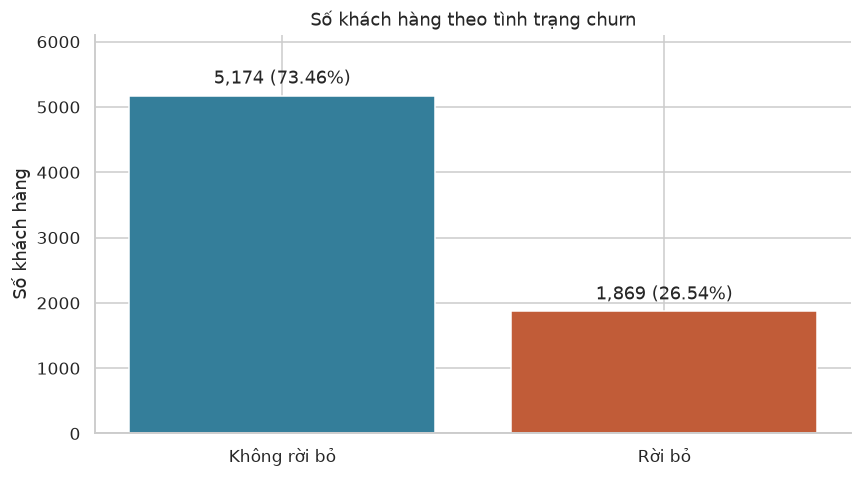

**Nhận xét:** Có **1,869/7,043** khách churn (**26.54%**). Giữ nguyên tỷ lệ này, không sinh mẫu cân bằng.

In [5]:
distribution = eda.groupby("Churn")["is_churn"].agg(n_customers="size", n_churn="sum").reindex(["No", "Yes"])
distribution["churn_rate"] = distribution["n_churn"] / distribution["n_customers"]
distribution["share_of_all"] = distribution["n_customers"] / len(eda)
display(distribution.assign(churn_rate=distribution['churn_rate'].map('{:.1%}'.format), share_of_all=distribution['share_of_all'].map('{:.2%}'.format)))
distribution.to_csv(TABLE_DIR / "churn_distribution.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(["Không rời bỏ", "Rời bỏ"], distribution["n_customers"], color=["#347E9A", "#C15C38"])
ax.set(title="Số khách hàng theo tình trạng churn", ylabel="Số khách hàng")
ax.set_ylim(0, distribution["n_customers"].max() * 1.18)
ax.bar_label(bars, labels=[f"{n:,} ({n/len(eda):.2%})" for n in distribution["n_customers"]], padding=5)
save_show(fig, "01_churn_distribution.png")
display(Markdown(f"**Nhận xét:** Có **{int(eda['is_churn'].sum()):,}/{len(eda):,}** khách churn "
                 f"(**{overall_rate:.2%}**). Giữ nguyên tỷ lệ này, không sinh mẫu cân bằng."))

### Hình 2 — Loại hợp đồng
So sánh tỷ lệ, không nhầm số khách churn nhiều với tỷ lệ churn cao.

,n_customers,n_churn,churn_rate,small_group
Contract,,,,
Month-to-month,3875,1655,42.71%,False
One year,1473,166,11.27%,False
Two year,1695,48,2.83%,False


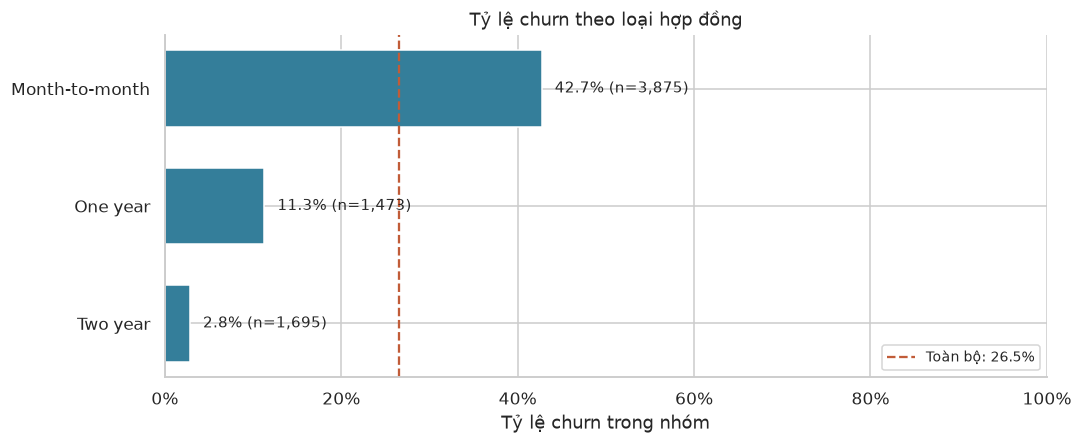

**Nhận xét:** Nhóm **Month-to-month** có tỷ lệ churn cao nhất trong bảng (42.71%, 1,655/3,875 khách); nhóm **Two year** là 2.83%. Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác.

In [6]:
contract = group_summary("Contract", ["Month-to-month", "One year", "Two year"])
fig, ax = plt.subplots(figsize=(10, 4.2))
rate_chart(contract, ax, "Tỷ lệ churn theo loại hợp đồng")
save_show(fig, "02_contract.png")
group_comment(contract)

### Hình 3 — Thời gian sử dụng
Ranh giới nhóm được khai báo trước, không lựa chọn ranh giới để tạo chênh lệch churn lớn nhất.

,n_customers,n_churn,churn_rate,small_group
TenureGroup,,,,
0–12,2186,1037,47.44%,False
13–24,1024,294,28.71%,False
25–48,1594,325,20.39%,False
>48,2239,213,9.51%,False


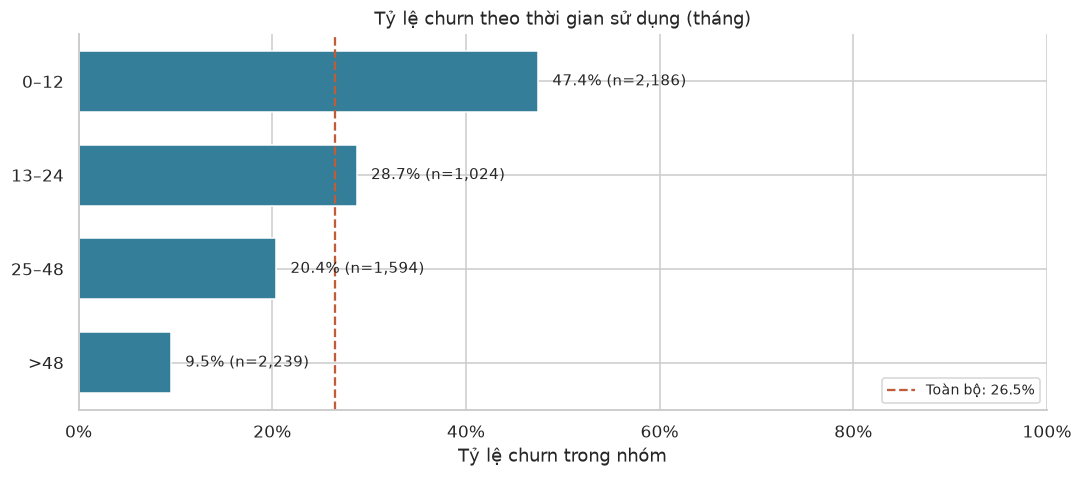

**Nhận xét:** Nhóm **0–12** có tỷ lệ churn cao nhất trong bảng (47.44%, 1,037/2,186 khách); nhóm **>48** là 9.51%. Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác.

In [7]:
tenure_table = group_summary("TenureGroup", TENURE_LABELS)
fig, ax = plt.subplots(figsize=(10, 4.5))
rate_chart(tenure_table, ax, "Tỷ lệ churn theo thời gian sử dụng (tháng)")
save_show(fig, "03_tenure.png")
group_comment(tenure_table)

### Hình 4 — Dịch vụ Internet
Nhóm `No` là không có dịch vụ Internet; đây là trạng thái hợp lệ, không phải dữ liệu thiếu.

,n_customers,n_churn,churn_rate,small_group
InternetService,,,,
DSL,2421,459,18.96%,False
Fiber optic,3096,1297,41.89%,False
No,1526,113,7.40%,False


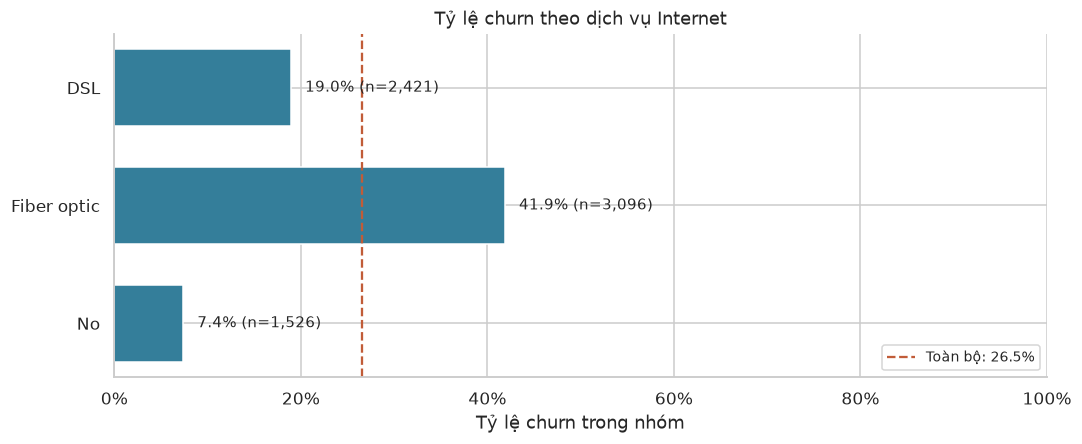

**Nhận xét:** Nhóm **Fiber optic** có tỷ lệ churn cao nhất trong bảng (41.89%, 1,297/3,096 khách); nhóm **No** là 7.40%. Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác.

In [8]:
internet = group_summary("InternetService", ["DSL", "Fiber optic", "No"])
fig, ax = plt.subplots(figsize=(10, 4.2))
rate_chart(internet, ax, "Tỷ lệ churn theo dịch vụ Internet")
save_show(fig, "04_internet.png")
group_comment(internet)

### Hình 5 — Hỗ trợ kỹ thuật và bảo mật trực tuyến
`No internet service` khác `No`: một bên không có Internet, bên kia có Internet nhưng không đăng ký dịch vụ bổ sung. Các quan hệ cấu trúc này cần được lưu ý khi lọc luật Apriori.

,n_customers,n_churn,churn_rate,small_group
TechSupport,,,,
No,3473,1446,41.64%,False
Yes,2044,310,15.17%,False
No internet service,1526,113,7.40%,False


,n_customers,n_churn,churn_rate,small_group
OnlineSecurity,,,,
No,3498,1461,41.77%,False
Yes,2019,295,14.61%,False
No internet service,1526,113,7.40%,False


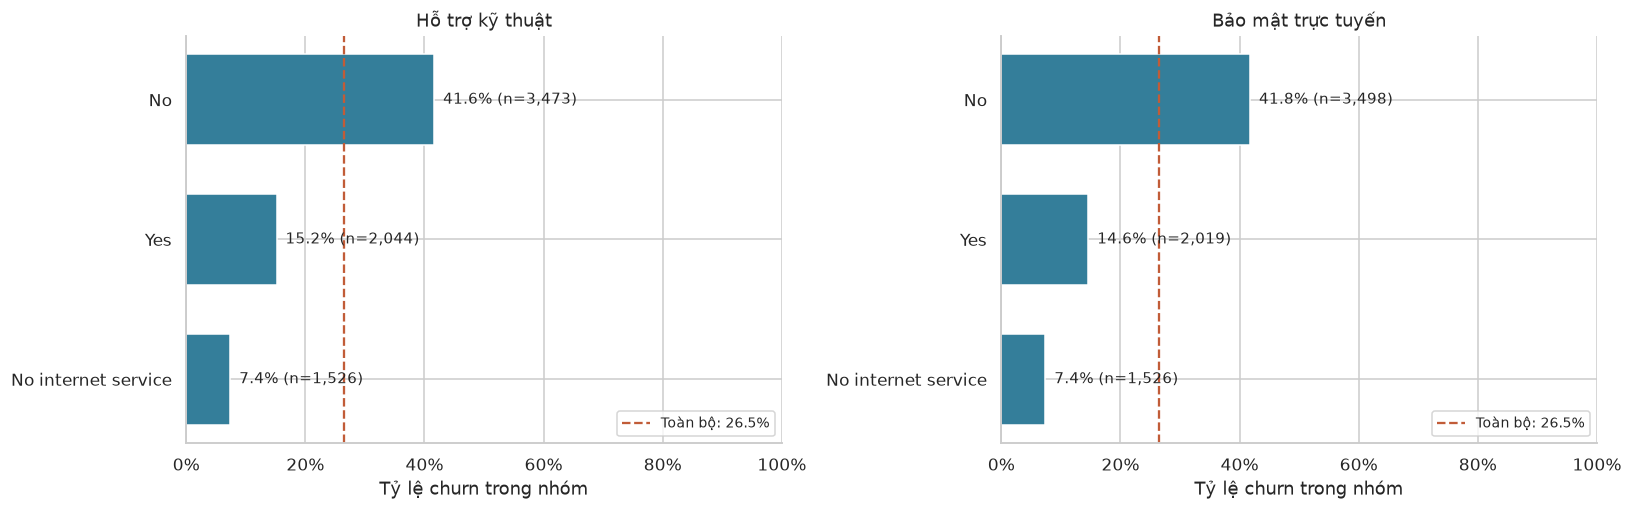

**Nhận xét:** Nhóm **No** có tỷ lệ churn cao nhất trong bảng (41.64%, 1,446/3,473 khách); nhóm **No internet service** là 7.40%. Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác.

**Nhận xét:** Nhóm **No** có tỷ lệ churn cao nhất trong bảng (41.77%, 1,461/3,498 khách); nhóm **No internet service** là 7.40%. Đây là liên hệ trong mẫu, chưa tách ảnh hưởng của các đặc điểm khác.

In [9]:
support = group_summary("TechSupport", ["No", "Yes", "No internet service"])
security = group_summary("OnlineSecurity", ["No", "Yes", "No internet service"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
rate_chart(support, axes[0], "Hỗ trợ kỹ thuật")
rate_chart(security, axes[1], "Bảo mật trực tuyến")
save_show(fig, "05_support_security.png")
group_comment(support)
group_comment(security)

### Hình 6 — Mức phí hằng tháng
Đường giữa hộp là trung vị; hộp chứa 50% giá trị ở giữa. Biểu đồ so sánh phân bố, không xác định một mức phí nào gây churn. Đơn vị giữ theo dữ liệu nguồn.

,n_customers,median,mean,q25,q75,n_churn,churn_rate
Churn,,,,,,,
No,5174,64.43,61.27,25.10,88.4,0,0.0%
Yes,1869,79.65,74.44,56.15,94.2,1869,100.0%


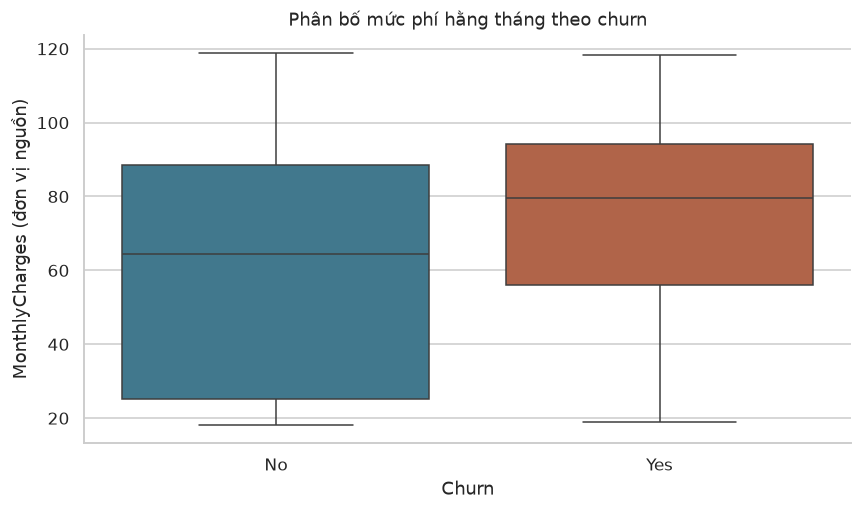

**Nhận xét:** Trung vị phí tháng của nhóm churn là **79.65**, của nhóm không churn là **64.43**. Hai phân bố vẫn chồng lấn; mức phí không quyết định chắc chắn một khách hàng sẽ rời bỏ.

In [10]:
charges = eda.groupby("Churn")["MonthlyCharges"].agg(
    n_customers="size", median="median", mean="mean",
    q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)).reindex(["No", "Yes"])
charges["n_churn"] = eda.groupby("Churn")["is_churn"].sum().reindex(charges.index)
charges["churn_rate"] = charges["n_churn"] / charges["n_customers"]
display(charges.round(2).assign(churn_rate=charges['churn_rate'].map('{:.1%}'.format)))
charges.to_csv(TABLE_DIR / "monthly_charges_by_churn.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", order=["No", "Yes"],
            hue="Churn", palette={"No": "#347E9A", "Yes": "#C15C38"}, legend=False, ax=ax)
ax.set(title="Phân bố mức phí hằng tháng theo churn", xlabel="Churn", ylabel="MonthlyCharges (đơn vị nguồn)")
save_show(fig, "06_monthly_charges.png")
display(Markdown(f"**Nhận xét:** Trung vị phí tháng của nhóm churn là **{charges.loc['Yes', 'median']:.2f}**, "
                 f"của nhóm không churn là **{charges.loc['No', 'median']:.2f}**. "
                 "Hai phân bố vẫn chồng lấn; mức phí không quyết định chắc chắn một khách hàng sẽ rời bỏ."))

## 4. Kiểm tra chéo và lưu dữ liệu bàn giao
Kiểm tra tổng khách và số churn của mọi bảng, kiểm tra riêng một nhóm bằng cách đếm trực tiếp. Bảng sạch có 20 cột, chưa thêm biến nhóm/nhãn số; Notebook 2 sẽ tự tạo các mục giao dịch từ bảng này.

Chỉ ghi vào các thư mục con `apriori`; không thay dữ liệu hay mô hình của luồng ML cũ.

In [11]:
# Đối chiếu một nhóm độc lập với hàm tổng hợp.
mask = clean["Contract"].eq("Month-to-month")
assert contract.loc["Month-to-month", "n_customers"] == int(mask.sum())
assert contract.loc["Month-to-month", "n_churn"] == int((mask & clean["Churn"].eq("Yes")).sum())
assert np.isclose(contract.loc["Month-to-month", "churn_rate"],
                  clean.loc[mask, "Churn"].eq("Yes").mean())
assert clean.loc[blank_total, "TotalCharges"].eq(0).all()
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == source_hash

clean_path = DATA_DIR / "telco_clean.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
reloaded = pd.read_csv(clean_path)
pd.testing.assert_frame_equal(clean.reset_index(drop=True), reloaded, check_dtype=False)
metadata = {
    "source": str(SOURCE.relative_to(ROOT)), "source_sha256": source_hash,
    "clean_sha256": hashlib.sha256(clean_path.read_bytes()).hexdigest(),
    "rows": len(clean), "columns": len(clean.columns),
    "churn_counts": {k: int(v) for k, v in clean["Churn"].value_counts().items()},
    "churn_rate": float(overall_rate), "blank_totalcharges_filled_zero": int(blank_total.sum()),
    "rows_dropped": 0, "analysis_scope": "Full dataset; descriptive, not predictive",
    "tenure_groups_for_eda": TENURE_LABELS,
    "python": platform.python_version(), "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
}
(DATA_DIR / "cleaning_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã kiểm tra: tổng khách, tổng churn, ranh giới tenure, một nhóm tính tay, CSV đọc lại và file gốc không đổi.")
print("Dữ liệu bàn giao:", clean_path)
print("Hình:", FIG_DIR)
display(clean.head())

Đã kiểm tra: tổng khách, tổng churn, ranh giới tenure, một nhóm tính tay, CSV đọc lại và file gốc không đổi.
Dữ liệu bàn giao: D:\vu\hoctap\Telco-Churn-Apriori\data\processed\apriori\telco_clean.csv
Hình: D:\vu\hoctap\Telco-Churn-Apriori\reports\apriori\figures


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Cách trình bày và giới hạn

**Tóm tắt để thuyết trình:**
> Em kiểm tra dữ liệu gốc, xử lý TotalCharges trống theo điều kiện tenure bằng 0 và loại mã định danh khỏi đầu vào. Em giữ nguyên khách hàng và tỷ lệ churn. Các bảng so sánh dùng tỷ lệ churn trong từng nhóm, có số khách làm căn cứ. Các phát hiện này định hướng tìm tổ hợp đặc điểm bằng Apriori, chưa phải nguyên nhân hoặc dự đoán.

**Câu hỏi tự kiểm tra:**
1. Vì sao bỏ customerID nhưng không xóa các khách hàng có hồ sơ giống nhau?
2. Vì sao điền 0 cho TotalCharges trong trường hợp này, không cho mọi ô thiếu?
3. Tỷ lệ churn của một nhóm có mẫu số là gì?
4. Vì sao không dùng SMOTE trong luồng Apriori?
5. Vì sao không được nói phí cao gây churn?

**Giới hạn:** dữ liệu dạng ảnh chụp, không mô tả diễn biến từng khách qua thời gian; phân tích mô tả chưa kiểm soát các yếu tố đồng thời; không khẳng định ý nghĩa thống kê vì notebook này không chạy kiểm định.

**Tiếp theo (chưa thực hiện ở đây):** Notebook 2 chia nhóm phí tháng, chuẩn bị 14 biến đầu vào cùng Churn, mã hóa Boolean và chạy Apriori. Notebook 3 chọn luật, diễn giải và kiểm tra độ nhạy theo support.